   Model  Proxy IS  Mean Shift  Classes Seen
VAE-like     5.377       0.295            10
GAN-like     5.073       0.389            10


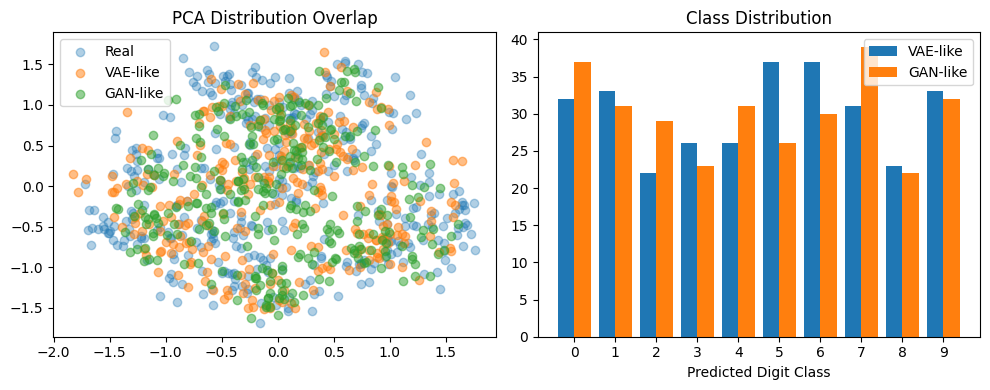

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from tensorflow.keras import layers, models

digits = load_digits()
X = (digits.data / 16.0).astype("float32")
y = digits.target

clf = models.Sequential([layers.Input(shape=(64,)), layers.Dense(64, activation="relu"), layers.Dense(10, activation="softmax")])
clf.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
clf.fit(X[:1400], y[:1400], epochs=15, batch_size=64, verbose=0)

# Create two synthetic sample sets (e.g., VAE-like vs GAN-like)
rng = np.random.default_rng(42)
vae_like = np.clip(X[rng.integers(0, 1400, 300)] + rng.normal(0, 0.08, (300, 64)), 0, 1)
gan_like = np.clip(X[rng.integers(0, 1400, 300)] + rng.normal(0, 0.15, (300, 64)), 0, 1)

def eval_set(arr, name):
    probs = clf.predict(arr, verbose=0)
    preds = np.argmax(probs, axis=1)
    marg = np.mean(probs, axis=0) + 1e-12
    # Proxy score combining confidence and class balance
    proxy_score = float(np.exp(np.mean(np.sum(probs * np.log(probs + 1e-12), axis=1) - np.sum(probs * np.log(marg), axis=1))))
    feat_dist = float(np.linalg.norm(arr.mean(axis=0) - X[1400:].mean(axis=0)))
    unique_cls = int(len(np.unique(preds)))
    return {"Model": name, "Proxy IS": round(proxy_score, 3), "Mean Shift": round(feat_dist, 3), "Classes Seen": unique_cls}, preds

r_vae, p_vae = eval_set(vae_like, "VAE-like")
r_gan, p_gan = eval_set(gan_like, "GAN-like")
print(pd.DataFrame([r_vae, r_gan]).to_string(index=False))

pca = PCA(n_components=2).fit(X[1400:])
z_real = pca.transform(X[1400:])
z_vae = pca.transform(vae_like)
z_gan = pca.transform(gan_like)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(z_real[:, 0], z_real[:, 1], alpha=0.35, label="Real")
axes[0].scatter(z_vae[:, 0], z_vae[:, 1], alpha=0.5, label="VAE-like")
axes[0].scatter(z_gan[:, 0], z_gan[:, 1], alpha=0.5, label="GAN-like")
axes[0].set_title("PCA Distribution Overlap"); axes[0].legend()

axes[1].hist([p_vae, p_gan], bins=np.arange(11)-0.5, label=["VAE-like", "GAN-like"])
axes[1].set_xticks(range(10)); axes[1].set_xlabel("Predicted Digit Class"); axes[1].set_title("Class Distribution"); axes[1].legend()
plt.tight_layout(); plt.show()